In [68]:
!pip install pandas numpy pyarrow scipy scikit-learn

In [69]:
import pandas as pd
import numpy as np
import os
import re

from datetime import datetime, timezone
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

In [70]:
os.makedirs("bronze", exist_ok=True)
os.makedirs("silver", exist_ok=True)
os.makedirs("gold", exist_ok=True)

print("Data Lake folders created!")

Data Lake folders created!


In [71]:
import pandas as pd
import csv

users = pd.read_csv(
    "BX-Users.csv",
    sep=";",
    encoding="latin-1"
)

books = pd.read_csv(
    "BX-Books.csv",
    sep=";",
    encoding="latin-1",
    engine="python",
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    "BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("All datasets loaded successfully!")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 815: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 1679: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 2531: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 2640: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 3236: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 3256: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 4906: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarning: Skipping line 6452: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_394/1229323452.py:10: ParserWarnin

All datasets loaded successfully!
Users: (278858, 3)
Books: (270491, 8)
Ratings: (1149780, 3)


In [72]:
timestamp = pd.Timestamp.now(tz="UTC")

users["ingestion_timestamp"] = timestamp
books["ingestion_timestamp"] = timestamp
ratings["ingestion_timestamp"] = timestamp

In [73]:
users.to_parquet(
    "bronze/users.parquet",
    index=False
)

books.to_parquet(
    "bronze/books.parquet",
    index=False
)

ratings.to_parquet(
    "bronze/ratings.parquet",
    index=False
)

print("Bronze layer created successfully!")

Bronze layer created successfully!


In [74]:
users_b = pd.read_parquet("bronze/users.parquet")
books_b = pd.read_parquet("bronze/books.parquet")
ratings_b = pd.read_parquet("bronze/ratings.parquet")

In [75]:
print("USERS")
print("Shape:", users_b.shape)
print(users_b.dtypes)
print(users_b.isnull().sum())

print("\nBOOKS")
print("Shape:", books_b.shape)
print(books_b.dtypes)
print(books_b.isnull().sum())

print("\nRATINGS")
print("Shape:", ratings_b.shape)
print(ratings_b.dtypes)
print(ratings_b.isnull().sum())

USERS
Shape: (278858, 4)
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

BOOKS
Shape: (270491, 9)
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
ingestion_timestamp    0
dtyp

In [76]:
print(ratings_b["Book-Rating"].value_counts().sort_index())

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


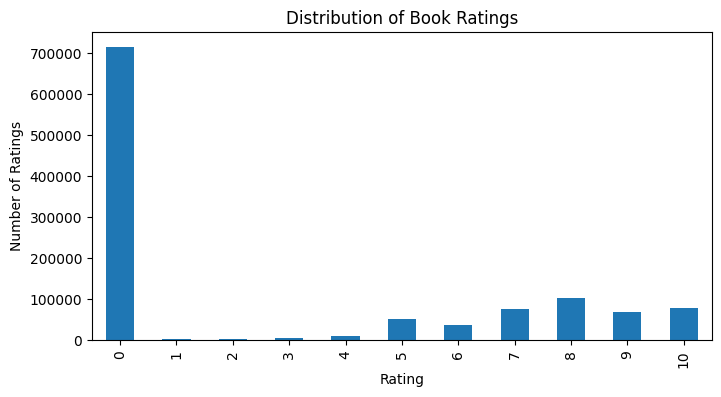

In [77]:
import matplotlib.pyplot as plt

ratings_b["Book-Rating"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Missing ages: 110762


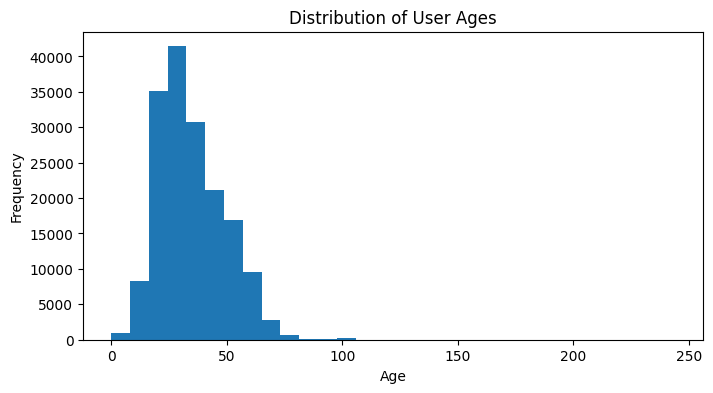

In [78]:
print(users_b["Age"].describe())

print("Missing ages:", users_b["Age"].isnull().sum())

users_b["Age"].plot(
    kind="hist",
    bins=30,
    figsize=(8, 4)
)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.show()

In [79]:
print("Age below 5:", (users_b["Age"] < 5).sum())

print("Age above 100:", (users_b["Age"] > 100).sum())

Age below 5: 882
Age above 100: 366


In [80]:
print(books_b["Year-Of-Publication"].describe())

print(
    books_b["Year-Of-Publication"]
    .value_counts()
    .sort_index()
)

count    270491.000000
mean       1959.704914
std         258.207234
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year-Of-Publication
0       4611
1376       1
1378       1
1806       1
1897       1
        ... 
2026       1
2030       7
2037       1
2038       1
2050       2
Name: count, Length: 116, dtype: int64


In [81]:
years = pd.to_numeric(
    books_b["Year-Of-Publication"],
    errors="coerce"
)

print("Year 0:", (years == 0).sum())

print(
    "Future publication years:",
    (years > datetime.now().year).sum()
)

Year 0: 4611
Future publication years: 11


In [82]:
user_rating_counts = ratings_b.groupby(
    "User-ID"
).size()

book_rating_counts = ratings_b.groupby(
    "ISBN"
).size()

print("User rating statistics:")
print(user_rating_counts.describe())

print("\nBook rating statistics:")
print(book_rating_counts.describe())

User rating statistics:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Book rating statistics:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


In [83]:
print(
    "Users with fewer than 10 ratings:",
    (user_rating_counts < 10).sum()
)

print(
    "Books with fewer than 10 ratings:",
    (book_rating_counts < 10).sum()
)

Users with fewer than 10 ratings: 92186
Books with fewer than 10 ratings: 322237


In [84]:
total_users = ratings_b["User-ID"].nunique()
total_books = ratings_b["ISBN"].nunique()

total_possible = total_users * total_books

actual_ratings = ratings_b[
    ratings_b["Book-Rating"] > 0
][["User-ID", "ISBN"]].drop_duplicates().shape[0]

sparsity = (
    1 - actual_ratings / total_possible
) * 100

print("Total possible user-book pairs:", total_possible)
print("Actual rated pairs:", actual_ratings)
print("Matrix sparsity:", round(sparsity, 2), "%")

Total possible user-book pairs: 35854757348
Actual rated pairs: 433671
Matrix sparsity: 100.0 %


In [85]:
users_s = pd.read_parquet("bronze/users.parquet")
books_s = pd.read_parquet("bronze/books.parquet")
ratings_s = pd.read_parquet("bronze/ratings.parquet")

In [86]:
users_s = users_s.drop_duplicates(
    subset=["User-ID"]
)

books_s = books_s.drop_duplicates(
    subset=["ISBN"]
)

ratings_s = ratings_s.drop_duplicates(
    subset=["User-ID", "ISBN"],
    keep="last"
)

print("Duplicates removed!")

Duplicates removed!


In [87]:
ratings_s = ratings_s[
    ratings_s["Book-Rating"].between(1, 10)
].copy()

print(ratings_s["Book-Rating"].value_counts().sort_index())

Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


In [88]:
users_s["Age"] = pd.to_numeric(
    users_s["Age"],
    errors="coerce"
)

users_s.loc[
    (users_s["Age"] < 5) | (users_s["Age"] > 100),
    "Age"
] = np.nan

median_age = users_s["Age"].median()

users_s["Age"] = users_s["Age"].fillna(
    median_age
)

users_s["Age"] = users_s["Age"].round().astype(int)

print("Median age:", median_age)
print("Remaining missing ages:", users_s["Age"].isnull().sum())

Median age: 32.0
Remaining missing ages: 0


In [89]:
location_parts = (
    users_s["Location"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.split(",", n=2, expand=True)
)

location_parts = location_parts.reindex(
    columns=range(3)
)

users_s["City"] = location_parts[0].str.strip()
users_s["State"] = location_parts[1].str.strip()
users_s["Country"] = location_parts[2].str.strip()

users_s = users_s.drop(columns=["Location"])

print(users_s[["City", "State", "Country"]].head())

          City            State         Country
0          nyc         new york             usa
1     stockton       california             usa
2       moscow  yukon territory          russia
3        porto         v.n.gaia        portugal
4  farnborough            hants  united kingdom


In [90]:
books_s["Year-Of-Publication"] = pd.to_numeric(
    books_s["Year-Of-Publication"],
    errors="coerce"
)

current_year = datetime.now().year

books_s.loc[
    (books_s["Year-Of-Publication"] == 0) |
    (books_s["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

print(
    books_s["Year-Of-Publication"].describe()
)

count    265869.000000
mean       1993.689212
std           8.324560
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Of-Publication, dtype: float64


In [91]:
def clean_text(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.title()
    )

books_s["Book-Title"] = clean_text(
    books_s["Book-Title"]
)

books_s["Book-Author"] = clean_text(
    books_s["Book-Author"]
)

users_s["City"] = clean_text(users_s["City"])
users_s["State"] = clean_text(users_s["State"])
users_s["Country"] = clean_text(users_s["Country"])

In [92]:
image_columns = [
    "Image-URL-S",
    "Image-URL-M",
    "Image-URL-L"
]

books_s = books_s.drop(
    columns=image_columns,
    errors="ignore"
)

print(books_s.head())

         ISBN                                         Book-Title  \
0  0195153448                                Classical Mythology   
1  0002005018                                       Clara Callan   
2  0060973129                               Decision In Normandy   
3  0374157065  Flu: The Story Of The Great Influenza Pandemic...   
4  0393045218                             The Mummies Of Urumchi   

            Book-Author  Year-Of-Publication                   Publisher  \
0    Mark P. O. Morford               2002.0     Oxford University Press   
1  Richard Bruce Wright               2001.0       HarperFlamingo Canada   
2          Carlo D'Este               1991.0             HarperPerennial   
3      Gina Bari Kolata               1999.0        Farrar Straus Giroux   
4       E. J. W. Barber               1999.0  W. W. Norton &amp; Company   

               ingestion_timestamp  
0 2026-11-26 13:13:51.028443+00:00  
1 2026-11-26 13:13:51.028443+00:00  
2 2026-11-26 13:13:51.0

In [93]:
valid_user_ids = set(users_s["User-ID"])

valid_book_isbns = set(books_s["ISBN"])

ratings_s = ratings_s[
    ratings_s["User-ID"].isin(valid_user_ids) &
    ratings_s["ISBN"].isin(valid_book_isbns)
].copy()

print("Valid ratings:", ratings_s.shape)

Valid ratings: (382827, 4)


In [94]:
MIN_RATINGS = 10

while True:

    previous_shape = ratings_s.shape[0]

    user_counts = ratings_s["User-ID"].value_counts()

    active_users = user_counts[
        user_counts >= MIN_RATINGS
    ].index

    ratings_s = ratings_s[
        ratings_s["User-ID"].isin(active_users)
    ].copy()

    book_counts = ratings_s["ISBN"].value_counts()

    popular_books = book_counts[
        book_counts >= MIN_RATINGS
    ].index

    ratings_s = ratings_s[
        ratings_s["ISBN"].isin(popular_books)
    ].copy()

    if ratings_s.shape[0] == previous_shape:
        break

print("Filtered ratings:", ratings_s.shape)

Filtered ratings: (41238, 4)


In [95]:
users_s = users_s[
    users_s["User-ID"].isin(ratings_s["User-ID"])
].copy()

books_s = books_s[
    books_s["ISBN"].isin(ratings_s["ISBN"])
].copy()

In [96]:
print("Users:", users_s.shape)
print("Books:", books_s.shape)
print("Ratings:", ratings_s.shape)

print(
    "Minimum user ratings:",
    ratings_s["User-ID"].value_counts().min()
)

print(
    "Minimum book ratings:",
    ratings_s["ISBN"].value_counts().min()
)

Users: (1813, 6)
Books: (2022, 6)
Ratings: (41238, 4)
Minimum user ratings: 10
Minimum book ratings: 10


I selected a minimum threshold of 10 ratings per user and book. This removes extremely inactive users and rarely rated books, helping make similarity calculations more meaningful while retaining a useful amount of data. The threshold was selected after examining the rating-count distributions during EDA.

In [97]:
users_s.to_parquet(
    "silver/users.parquet",
    index=False
)

books_s.to_parquet(
    "silver/books.parquet",
    index=False
)

ratings_s.to_parquet(
    "silver/ratings.parquet",
    index=False
)

print("Silver layer created successfully!")

Silver layer created successfully!


In [98]:
users_s = pd.read_parquet("silver/users.parquet")
books_s = pd.read_parquet("silver/books.parquet")
ratings_s = pd.read_parquet("silver/ratings.parquet")

In [99]:
user_ids = sorted(ratings_s["User-ID"].unique())

book_ids = sorted(ratings_s["ISBN"].unique())

user_to_index = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

book_to_index = {
    book_id: index
    for index, book_id in enumerate(book_ids)
}

In [100]:
row_indices = ratings_s["ISBN"].map(book_to_index)

col_indices = ratings_s["User-ID"].map(user_to_index)

data = ratings_s["Book-Rating"].values

user_book_matrix = csr_matrix(
    (
        data,
        (row_indices, col_indices)
    ),
    shape=(len(book_ids), len(user_ids))
)

print("Matrix shape:", user_book_matrix.shape)
print("Non-zero ratings:", user_book_matrix.nnz)

Matrix shape: (2022, 1813)
Non-zero ratings: 41238


In [101]:
save_npz(
    "gold/user_book_matrix.npz",
    user_book_matrix
)

In [102]:
pd.DataFrame({
    "ISBN": book_ids,
    "matrix_index": range(len(book_ids))
}).to_parquet(
    "gold/book_index.parquet",
    index=False
)

pd.DataFrame({
    "User-ID": user_ids,
    "matrix_index": range(len(user_ids))
}).to_parquet(
    "gold/user_index.parquet",
    index=False
)

In [103]:
book_lookup = books_s[
    ["ISBN", "Book-Title", "Book-Author"]
].drop_duplicates("ISBN")

book_lookup.to_parquet(
    "gold/book_lookup.parquet",
    index=False
)

print(book_lookup.head())

         ISBN                            Book-Title       Book-Author
0  0440234743                         The Testament      John Grisham
1  0452264464  Beloved (Plume Contemporary Fiction)     Toni Morrison
2  0971880107                           Wild Animus      Rich Shapero
3  0345402871                              Airframe  Michael Crichton
4  0345417623                              Timeline  Michael Crichton


In [104]:
user_aggregates = ratings_s.groupby(
    "User-ID"
).agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

user_aggregates.to_parquet(
    "gold/user_aggregates.parquet",
    index=False
)

print(user_aggregates.head())

   User-ID  average_rating  number_of_ratings
0      243        7.769231                 13
1      254        8.450000                 20
2      638        9.454545                 22
3      805        8.400000                 10
4      882        8.235294                 17


In [105]:
book_aggregates = ratings_s.groupby(
    "ISBN"
).agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates = book_aggregates.merge(
    book_lookup,
    on="ISBN",
    how="left"
)

book_aggregates.to_parquet(
    "gold/book_aggregates.parquet",
    index=False
)

print(book_aggregates.head())

         ISBN  average_rating  number_of_ratings  \
0  0020199600        8.090909                 11   
1  0020442203        8.833333                 12   
2  002542730X        7.481481                 27   
3  0028604199        7.900000                 10   
4  0060002050        7.545455                 11   

                                          Book-Title          Book-Author  
0                             Great Gatsby (Reissue)  F. Scott Fitzgerald  
1                   Lion, The Witch And The Wardrobe           C.S. Lewis  
2  Politically Correct Bedtime Stories: Modern Ta...    James Finn Garner  
3  Once Upon A More Enlightened Time: More Politi...    James Finn Garner  
4                  On A Wicked Dawn (Cynster Novels)    Stephanie Laurens  


In [106]:
user_book_matrix = load_npz(
    "gold/user_book_matrix.npz"
)

book_index = pd.read_parquet(
    "gold/book_index.parquet"
)

user_index = pd.read_parquet(
    "gold/user_index.parquet"
)

book_lookup = pd.read_parquet(
    "gold/book_lookup.parquet"
)

print(user_book_matrix.shape)

(2022, 1813)


In [107]:
number_of_books = user_book_matrix.shape[0]

model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=min(11, number_of_books)
)

model.fit(user_book_matrix)

print("Book similarity model trained!")

Book similarity model trained!


In [108]:
def find_similar_books(book_title, n=10):

    # Find the book using its title
    matches = book_lookup[
        book_lookup["Book-Title"].str.lower()
        == book_title.strip().lower()
    ]

    if matches.empty:
        return "Book not found!"

    isbn = matches.iloc[0]["ISBN"]

    # Find the matrix index
    book_row = book_index[
        book_index["ISBN"] == isbn
    ]["matrix_index"].iloc[0]

    # Find similar books
    distances, indices = model.kneighbors(
        user_book_matrix[book_row],
        n_neighbors=min(n + 1, number_of_books)
    )

    results = []

    for distance, index in zip(
        distances[0], indices[0]
    ):

        if index == book_row:
            continue

        similarity = 1 - distance

        similar_isbn = book_index.loc[
            book_index["matrix_index"] == index,
            "ISBN"
        ].iloc[0]

        book_info = book_lookup[
            book_lookup["ISBN"] == similar_isbn
        ]

        results.append({
            "Book Title": book_info.iloc[0]["Book-Title"],
            "Author": book_info.iloc[0]["Book-Author"],
            "Similarity": round(float(similarity), 4)
        })

    return pd.DataFrame(results).head(n)

In [109]:
find_similar_books(
    book_lookup.iloc[0]["Book-Title"],
    n=10
)

,Book Title,Author,Similarity
0,Monster : A Novel (Alex Delaware Novels (Paper...,Jonathan Kellerman,0.2528
1,The Runaway Jury,John Grisham,0.2378
2,The Bone Collector (Lincoln Rhyme Novels (Pape...,Jeff Deaver,0.2376
3,Call Of The Wild,Jack London,0.2359
4,The Simple Truth,David Baldacci,0.2356
5,The Street Lawyer,John Grisham,0.2198
6,Atlantis Found,Clive Cussler,0.1994
7,Outbreak,Robin Cook,0.1987
8,From Potter'S Field,Patricia Daniels Cornwell,0.1962
9,Writ Of Execution,Perri O'Shaughnessy,0.1901


In [110]:
def recommend(user_id, n=10):

    user_ratings = ratings_s[
        ratings_s["User-ID"] == user_id
    ].copy()

    if user_ratings.empty:
        return pd.DataFrame(
            columns=["Book Title", "Author", "Score"]
        )

    liked_books = user_ratings[
        user_ratings["Book-Rating"] >= 7
    ]

    if liked_books.empty:
        return pd.DataFrame(
            columns=["Book Title", "Author", "Score"]
        )

    already_read_isbns = set(user_ratings["ISBN"])
    already_read_titles = set(
        book_lookup.loc[
            book_lookup["ISBN"].isin(already_read_isbns),
            "Book-Title"
        ].str.lower()
    )

    recommendation_scores = {}

    for _, row in liked_books.iterrows():

        isbn = row["ISBN"]
        user_rating = row["Book-Rating"]

        book_row = book_index.loc[
            book_index["ISBN"] == isbn,
            "matrix_index"
        ].iloc[0]

        distances, indices = model.kneighbors(
            user_book_matrix[book_row],
            n_neighbors=min(21, number_of_books)
        )

        for distance, index in zip(
            distances[0], indices[0]
        ):

            candidate_isbn = book_index.loc[
                book_index["matrix_index"] == index,
                "ISBN"
            ].iloc[0]

            if candidate_isbn in already_read_isbns:
                continue

            book_info = book_lookup[book_lookup["ISBN"] == candidate_isbn]
            if book_info.empty:
                continue

            candidate_title = book_info.iloc[0]["Book-Title"].lower()
            if candidate_title in already_read_titles:
                continue

            similarity = 1 - distance

            score = similarity * user_rating

            recommendation_scores[candidate_isbn] = (
                recommendation_scores.get(candidate_isbn, 0)
                + score
            )

    if not recommendation_scores:
        return pd.DataFrame(
            columns=["Book Title", "Author", "Score"]
        )

    top_books = sorted(
        recommendation_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    result = pd.DataFrame(
        top_books,
        columns=["ISBN", "Score"]
    )

    result = result.merge(
        book_lookup,
        on="ISBN",
        how="left"
    )

    result = result.rename(
        columns={
            "Book-Title": "Book Title",
            "Book-Author": "Author"
        }
    )

    return result[
        ["Book Title", "Author", "Score"]
    ].reset_index(drop=True)

In [111]:
high_rating_counts = (
    ratings_s[ratings_s["Book-Rating"] >= 7]
    .groupby("User-ID")
    .size()
)

demo_users = high_rating_counts[
    high_rating_counts >= 3
].head(3).index.tolist()

print("Selected users:", demo_users)

Selected users: [243, 254, 638]


In [112]:
for user_id in demo_users:

    print("\n" + "=" * 60)
    print("USER ID:", user_id)

    liked = ratings_s[
        (ratings_s["User-ID"] == user_id) &
        (ratings_s["Book-Rating"] >= 7)
    ].merge(
        book_lookup,
        on="ISBN",
        how="left"
    )

    print("\nBooks rated highly by the user:")

    print(
        liked[
            ["Book-Title", "Book-Author", "Book-Rating"]
        ].head(10).to_string(index=False)
    )

    # Recommendations
    recommendations = recommend(user_id, n=10)

    print("\nRecommended Books:")

    if recommendations.empty:
        print("No recommendations available.")

    else:
        print(recommendations.to_string(index=False))


USER ID: 243

Books rated highly by the user:
                Book-Title               Book-Author  Book-Rating
            The Bean Trees        Barbara Kingsolver           10
   The God Of Small Things             Arundhati Roy            7
The Pilot'S Wife : A Novel              Anita Shreve            9
    Me Talk Pretty One Day             David Sedaris            9
     River, Cross My Heart             Breena Clarke            7
       Memoirs Of A Geisha             Arthur Golden           10
        A Map Of The World             Jane Hamilton            7
        Unnatural Exposure Patricia Daniels Cornwell            9
           A Painted House              John Grisham            7
    The General'S Daughter            Nelson Demille            9

Recommended Books:
                                  Book Title                    Author    Score
                       We Were The Mulvaneys         Joyce Carol Oates 5.903687
Vinegar Hill (Oprah'S Book Club (Paperback))   

In [113]:
for user_id in demo_users:

    recs = recommend(user_id, n=10)

    # Get titles of books already rated by the user
    already_read_isbns = ratings_s.loc[
        ratings_s["User-ID"] == user_id,
        "ISBN"
    ]

    already_read_titles = set(
        book_lookup.loc[
            book_lookup["ISBN"].isin(already_read_isbns),
            "Book-Title"
        ].str.lower()
    )

    # Get recommended titles
    recommended_titles = set(recs["Book Title"].str.lower())

    # Find intersection of titles
    overlapping_titles = already_read_titles.intersection(recommended_titles)
    if overlapping_titles:
        print(f"\nWARNING: Found overlapping titles for user {user_id}: {overlapping_titles}")

    # Check that no already-read book title is recommended
    assert len(overlapping_titles) == 0, (
        f"Already-read book found for user {user_id}! Overlaps: {overlapping_titles}"
    )

    print(
        f"User {user_id}: "
        f"{len(recs)} recommendations generated. "
        "No already-rated books included."
    )

User 243: 10 recommendations generated. No already-rated books included.
User 254: 10 recommendations generated. No already-rated books included.
User 638: 10 recommendations generated. No already-rated books included.


In [114]:
for folder in ["bronze", "silver", "gold"]:
    print(folder, ":", os.listdir(folder))

bronze : ['users.parquet', 'books.parquet', 'ratings.parquet']
silver : ['users.parquet', 'books.parquet', 'ratings.parquet']
gold : ['book_index.parquet', 'user_aggregates.parquet', 'user_book_matrix.npz', 'user_index.parquet', 'book_lookup.parquet', 'book_aggregates.parquet']


In [115]:
print("Gold matrix:", user_book_matrix.shape)

print("Number of users:", len(user_ids))

print("Number of books:", len(book_ids))

print("Total ratings:", user_book_matrix.nnz)

print("Sparsity:",
      round(
          (1 - user_book_matrix.nnz /
           (user_book_matrix.shape[0] *
            user_book_matrix.shape[1])) * 100,
          2
      ),
      "%")

Gold matrix: (2022, 1813)
Number of users: 1813
Number of books: 2022
Total ratings: 41238
Sparsity: 98.88 %
